# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how risky its revenue is. The previous version of this question modelled the stock with Fibonacci numbers and flagged risk when revenue variance exceeded 50,000. This notebook builds a more defensible model and explains why the old approach is flawed.

All logic is in [`src/fishery.py`](src/fishery.py). Parameters follow the brief (r = 0.4 per week, K = 10,000 t, N₀ = 4,000 t). Prices are a **synthetic**, seeded random walk.

**Assumptions I made.**
* Harvest is *proportional*: each week the cooperative lands a fraction $h$ of the current stock, as the brief's equation implies.
* $h = 0.10$ is the "current" baseline rate used for the single-path statistics and the Monte Carlo VaR.
* Price shocks have a weekly SD of UGX 400/kg and are clipped to UGX 9,000–16,000/kg.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.fishery import FishStock, PriceModel, RiskAssessor, fibonacci, weekly_revenue

SEED = 2026
WEEKS = 52
BASELINE_H = 0.10
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Baseline: Fibonacci "stock"

In [2]:
fib = fibonacci(15)
print("15 Fibonacci numbers:", fib)
print("Successive ratios:", np.round(np.array(fib[1:]) / np.array(fib[:-1]), 4)[-5:], "-> golden ratio 1.618")

15 Fibonacci numbers: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Successive ratios: [1.6182 1.618  1.6181 1.618  1.618 ] -> golden ratio 1.618


**Why unbounded Fibonacci growth is biologically unrealistic.** Fibonacci growth assumes every pair of fish reproduces on a fixed schedule and that nothing ever dies, so the stock grows by about 61.8% per period *for ever*: 15 steps take it from 1 to 610, and 50 steps would exceed 12 billion. A real lake has a finite **carrying capacity**: food (haplochromines, insects, zooplankton), oxygen and breeding habitat are limited, so per-capita growth slows as density rises. The model also has no natural mortality, predation or disease, and, crucially for this question, **no harvesting term**. It therefore cannot even express the cooperative's decision. A model that never stops growing would declare *any* harvest rate sustainable, which is the most dangerous possible answer for a fishery manager.

## 2. `FishStock`: logistic growth with harvesting

$$N_{t+1} = N_t + rN_t\left(1 - \frac{N_t}{K}\right) - hN_t$$

With constant $h < r$ the stock settles at $N^* = K(1 - h/r)$ and the long-run catch is $hN^* = hK(1 - h/r)$. This is maximised at $h = r/2$, which gives **MSY = rK/4**.

In [3]:
stock = FishStock(r=0.4, K=10_000, N0=4_000, h=BASELINE_H)
traj = stock.simulate(WEEKS)
print(stock)
print(f"Week 0: {traj.stock[0]:,.0f} t -> week 52: {traj.final_stock:,.0f} t (theory N* = {stock.equilibrium_stock:,.0f} t)")
print(f"Total 52-week catch: {traj.total_harvest:,.0f} t; mean {traj.harvest.mean():,.1f} t/week")
# Hand check of the first step
n0 = 4000
print(f"Hand check week 1: 4000 + 0.4*4000*(1-0.4) - 0.1*4000 = {n0 + 0.4 * n0 * (1 - n0 / 10000) - 0.1 * n0:,.0f} vs model {traj.stock[1]:,.0f}")

FishStock(r=0.4, K=10000, N0=4000, h=0.1)
Week 0: 4,000 t -> week 52: 7,500 t (theory N* = 7,500 t)
Total 52-week catch: 37,363 t; mean 718.5 t/week
Hand check week 1: 4000 + 0.4*4000*(1-0.4) - 0.1*4000 = 4,560 vs model 4,560


## 3. `PriceModel` and weekly revenue

In [4]:
price_model = PriceModel(start=12_000, step_sd=400, lower=9_000, upper=16_000)
rng = np.random.default_rng(SEED)
price = price_model.simulate(WEEKS, rng)
revenue = weekly_revenue(traj.harvest, price)
print(price_model)
print(f"Price range over the year: UGX {price.min():,.0f} - {price.max():,.0f}/kg")
print(f"Week 1 revenue: {traj.harvest[0]:,.1f} t x 1000 kg/t x UGX {price[0]:,.0f}/kg = UGX {revenue[0]:,.0f}")

PriceModel(start=12000, sd=400, bounds=[9000, 16000])
Price range over the year: UGX 11,020 - 16,000/kg
Week 1 revenue: 400.0 t x 1000 kg/t x UGX 12,000/kg = UGX 4,800,000,000


## 4. Revenue statistics and why "variance > 50,000" is meaningless

In [5]:
assessor = RiskAssessor(low_threshold=0.10, high_threshold=0.25, var_level=0.05)
rev_stats = assessor.describe(revenue)
pd.Series(rev_stats, name="weekly revenue (UGX)").to_frame().style.format("{:,.4g}")

,weekly revenue (UGX)
mean,8.862e+09
median,8.893e+09
variance,1.851e+18
std,1.36e+09
cv,0.1535


In [6]:
rev_m = revenue / 1e6  # same data in millions of UGX
print(f"Variance in UGX²            : {RiskAssessor.describe(revenue)['variance']:.3e}")
print(f"Variance in (million UGX)²  : {RiskAssessor.describe(rev_m)['variance']:.3e}")
print(f"CV in UGX / in million UGX  : {RiskAssessor.describe(revenue)['cv']:.4f} / {RiskAssessor.describe(rev_m)['cv']:.4f}")

Variance in UGX²            : 1.851e+18
Variance in (million UGX)²  : 1.851e+06
CV in UGX / in million UGX  : 0.1535 / 0.1535


**Why a raw variance threshold is meaningless.** Variance is measured in the *square* of the data's units, here **UGX²**. Weekly revenue is in the billions of shillings, so its variance is around $10^{17}$ UGX², and "variance > 50,000" flags *every* scenario, however stable. Rescale the same data to millions of UGX and the variance falls by a factor of $10^{12}$, even though the risk has not changed at all. The threshold also ignores scale: a ±UGX 1 million swing is a crisis for a small landing site and noise for a large exporter.

The **coefficient of variation** $\text{CV} = s/\bar x$ fixes both problems. It is dimensionless (identical in UGX or millions of UGX, as shown above) and expresses volatility *relative to typical income*.

## 5. `RiskAssessor`: a justified CV rule and Monte Carlo VaR

**Rule** (applied to the weekly revenue series):

| CV of weekly revenue | Class | Reasoning |
|---|---|---|
| < 0.10 | Low | A typical week is within ±10% of normal income, so a cash buffer of a couple of weeks smooths it out |
| 0.10 – 0.25 | Moderate | Swings of 10–25% need active cash management (reserves, staggered member payments) |
| ≥ 0.25 | High | A typical week is off by a quarter or more; the price band alone (±25–33% around UGX 12,000) cannot produce this, so it signals the catch itself is unstable |

The thresholds were fixed *before* looking at the scenario results, to avoid fitting the rule to the answer.

**VaR.** I simulate 2,000 independent 52-week price paths. Annual revenue is $\sum_t \text{harvest}_t \times 1000 \times P_t$. The 5% VaR is the 5th percentile of that distribution: in 95% of years the cooperative earns at least this much. I also report it as a *shortfall* below expected revenue.

In [7]:
N_PATHS = 2000
paths = price_model.simulate_paths(N_PATHS, WEEKS, np.random.default_rng(SEED + 1))
annual = weekly_revenue(traj.harvest, paths).sum(axis=1)
var = assessor.value_at_risk(annual)
print(f"Risk class (h = {BASELINE_H}): {assessor.classify(revenue)}  (weekly CV = {rev_stats['cv']:.3f})")
print(f"Expected annual revenue : UGX {var['mean'] / 1e9:,.1f} bn")
print(f"5% quantile (VaR level) : UGX {var['quantile'] / 1e9:,.1f} bn")
print(f"5% VaR as shortfall     : UGX {var['var_shortfall'] / 1e9:,.1f} bn ({var['var_shortfall'] / var['mean']:.1%} below expected)")

Risk class (h = 0.1): Moderate  (weekly CV = 0.154)
Expected annual revenue : UGX 452.4 bn
5% quantile (VaR level) : UGX 374.7 bn
5% VaR as shortfall     : UGX 77.7 bn (17.2% below expected)


## 6. Scenario analysis: h = 0.05, 0.10, 0.20, 0.30

All scenarios use the **same** price path for the risk class and the **same** 2,000 Monte Carlo paths (common random numbers). Differences between scenarios therefore come from the harvest policy, not from luck.

In [8]:
H_VALUES = [0.05, 0.10, 0.20, 0.30]
rows, trajectories, annual_by_h = [], {}, {}
for h in H_VALUES:
    fs = FishStock(r=0.4, K=10_000, N0=4_000, h=h)
    tr = fs.simulate(WEEKS)
    trajectories[h] = tr
    rev = weekly_revenue(tr.harvest, price)
    ann = weekly_revenue(tr.harvest, paths).sum(axis=1)
    annual_by_h[h] = ann
    v = assessor.value_at_risk(ann)
    cv = assessor.describe(rev)["cv"]
    rows.append({
        "h": h,
        "final stock (t)": tr.final_stock,
        "total revenue (bn UGX)": rev.sum() / 1e9,
        "weekly CV": cv,
        "risk class": assessor.classify_cv(cv),
        "5% VaR shortfall (bn UGX)": v["var_shortfall"] / 1e9,
        "mean catch (t/wk)": tr.harvest.mean(),
        "long-run catch hK(1-h/r) (t/wk)": fs.equilibrium_yield,
        "% of MSY (long run)": fs.equilibrium_yield / fs.msy * 100,
        "sustainable?": "yes" if h <= fs.msy_rate else "no: beyond MSY rate",
    })
scenarios = pd.DataFrame(rows).set_index("h")
print(f"MSY = rK/4 = {stock.msy:,.0f} t/week, achieved at h = r/2 = {stock.msy_rate}")
scenarios

MSY = rK/4 = 1,000 t/week, achieved at h = r/2 = 0.2

,final stock (t),total revenue (bn UGX),weekly CV,risk class,5% VaR shortfall (bn UGX),mean catch (t/wk),long-run catch hK(1-h/r) (t/wk),% of MSY (long run),sustainable?
h,,,,,,,,,
0.050,"8,750.000",267.886,0.166,Moderate,45.395,417.589,437.500,43.750,yes
0.100,"7,500.000",460.842,0.154,Moderate,77.747,718.510,750.000,75.000,yes
0.200,"4,999.988",626.788,0.112,Moderate,103.865,978.302,"1,000.000",100.000,yes
0.300,"2,503.717",520.539,0.121,Moderate,82.336,816.558,750.000,75.000,no: beyond MSY rate


**Comparison with MSY.** Only $h = 0.20 = r/2$ reaches the theoretical MSY of 1,000 t/week in the long run. Both $h = 0.10$ and $h = 0.30$ settle at 750 t/week (75% of MSY), but for very different reasons. At $h = 0.10$ the stock stays large (7,500 t) and resilient. At $h = 0.30$ the cooperative is fishing harder for the *same* long-run catch from a stock reduced to 2,500 t, a quarter of carrying capacity, so it is more exposed to a bad recruitment year or an environmental shock. Year-1 figures flatter $h = 0.30$: its mean catch (817 t/week) is *above* its long-run 750 because it starts by mining the initial 4,000 t down to 2,500. That one-off windfall is not repeatable.

**Risk classes.** All four policies come out *Moderate* (weekly CV 0.11–0.17). Risk relative to income barely changes with $h$, because the price path, which is the main source of volatility, is the same for all of them. The highest CV belongs to $h = 0.05$, and that is *not* because it is riskier. Its catch roughly doubles during the year as the stock recovers, and a weekly CV cannot tell an upward trend from volatility. This is a limitation of the rule (see below). The 5% VaR shortfall grows with expected revenue, staying around 16–17% of the mean in every case.

## 7. Charts

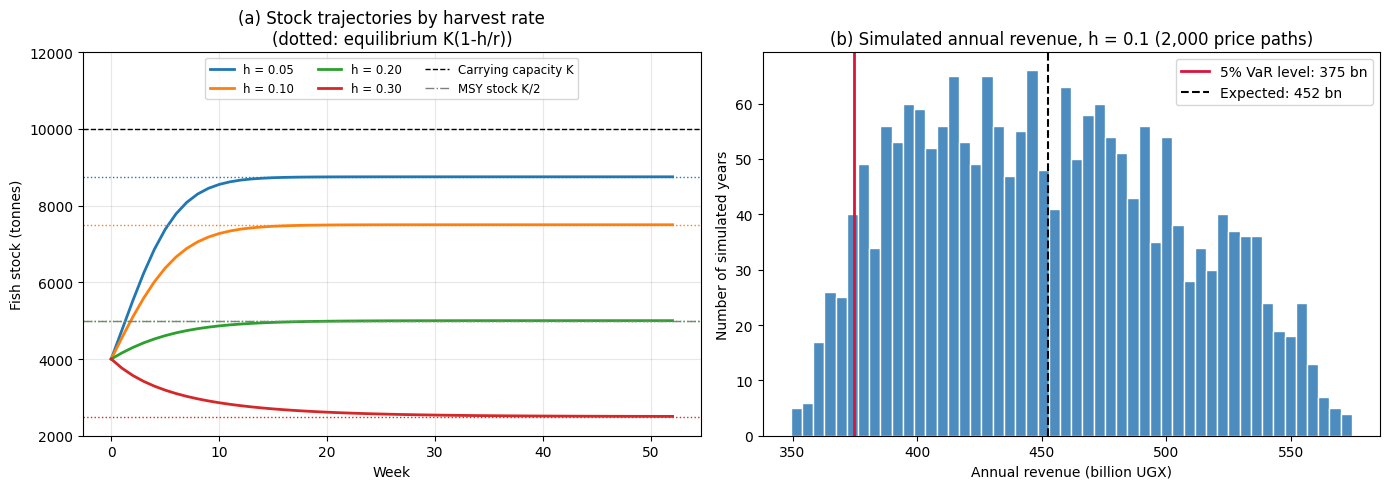

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for i, h in enumerate(H_VALUES):
    ax.plot(trajectories[h].stock, color=f"C{i}", lw=2, label=f"h = {h:.2f}")
    ax.axhline(FishStock(h=h).equilibrium_stock, color=f"C{i}", ls=":", lw=1)
ax.axhline(10_000, color="k", ls="--", lw=1, label="Carrying capacity K")
ax.axhline(5_000, color="0.5", ls="-.", lw=1, label="MSY stock K/2")
ax.set_xlabel("Week")
ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("(a) Stock trajectories by harvest rate\n(dotted: equilibrium K(1-h/r))")
ax.set_ylim(2000, 12000)
ax.legend(loc="upper center", ncol=3, fontsize=8.5)
ax.grid(alpha=0.3)

ax = axes[1]
base_ann = annual_by_h[BASELINE_H] / 1e9
v = assessor.value_at_risk(annual_by_h[BASELINE_H])
ax.hist(base_ann, bins=50, color="#4c8cbf", edgecolor="white")
ax.axvline(v["quantile"] / 1e9, color="crimson", lw=2, label=f"5% VaR level: {v['quantile'] / 1e9:,.0f} bn")
ax.axvline(v["mean"] / 1e9, color="k", ls="--", lw=1.5, label=f"Expected: {v['mean'] / 1e9:,.0f} bn")
ax.set_xlabel("Annual revenue (billion UGX)")
ax.set_ylabel("Number of simulated years")
ax.set_title(f"(b) Simulated annual revenue, h = {BASELINE_H} ({N_PATHS:,} price paths)")
ax.legend()
fig.tight_layout()
plt.show()

## Extension: an 8-week closed season over 5 years

I close the fishery for **weeks 14–21 of each year** (roughly April–May, the long rains, when many Lake Victoria species breed). Uganda has periodically used seasonal and area closures. The exact weeks here are an assumption. Each policy runs for 260 weeks and is priced on the same 2,000 five-year price paths.

In [10]:
YEARS5 = 5
W5 = WEEKS * YEARS5
CLOSED = range(14, 22)
paths5 = price_model.simulate_paths(N_PATHS, W5, np.random.default_rng(SEED + 2))
ext_rows, ext_traj = [], {}
for h in H_VALUES:
    for label, closed in [("open all year", ()), ("8-week closure", CLOSED)]:
        tr = FishStock(h=h, closed_weeks=closed).simulate(W5)
        ext_traj[(h, label)] = tr
        rev5 = weekly_revenue(tr.harvest, paths5).sum(axis=1)
        ext_rows.append({"h": h, "policy": label, "5-yr catch (t)": tr.total_harvest,
                         "expected 5-yr revenue (bn UGX)": rev5.mean() / 1e9,
                         "5% quantile (bn UGX)": np.quantile(rev5, 0.05) / 1e9,
                         "min stock in year 5 (t)": tr.stock[-WEEKS:].min()})
ext = pd.DataFrame(ext_rows).set_index(["h", "policy"])
effect = (ext.xs("8-week closure", level="policy")["expected 5-yr revenue (bn UGX)"]
          / ext.xs("open all year", level="policy")["expected 5-yr revenue (bn UGX)"] - 1) * 100
display(ext)
print("Effect of closure on expected 5-year revenue (%):")
print(effect.round(1).to_string())

5-yr catch (t)  expected 5-yr revenue (bn UGX)  \
h     policy                                                           
0.050 open all year      112,714.612                       1,388.355   
      8-week closure      96,025.733                       1,183.114   
0.100 open all year      193,362.508                       2,381.684   
      8-week closure     166,791.469                       2,054.929   
0.200 open all year      258,871.699                       3,188.236   
      8-week closure     234,746.975                       2,891.692   
0.300 open all year      198,472.161                       2,443.050   
      8-week closure     212,732.219                       2,619.228   

                      5% quantile (bn UGX)  min stock in year 5 (t)  
h     policy                                                         
0.050 open all year              1,165.942                8,750.000  
      8-week closure               992.552                8,750.000  
0.100 open all year              2,000.404                7,500.000  
      8-week closure             1,724.092                7,500.000  
0.200 open all year              2,679.157                5,000.000  
      8-week closure             2,427.999                5,000.111  
0.300 open all year              2,060.093                2,500.000  
      8-week closure             2,203.635                2,515.133

Effect of closure on expected 5-year revenue (%):
h
0.050   -14.800
0.100   -13.700
0.200    -9.300
0.300     7.200


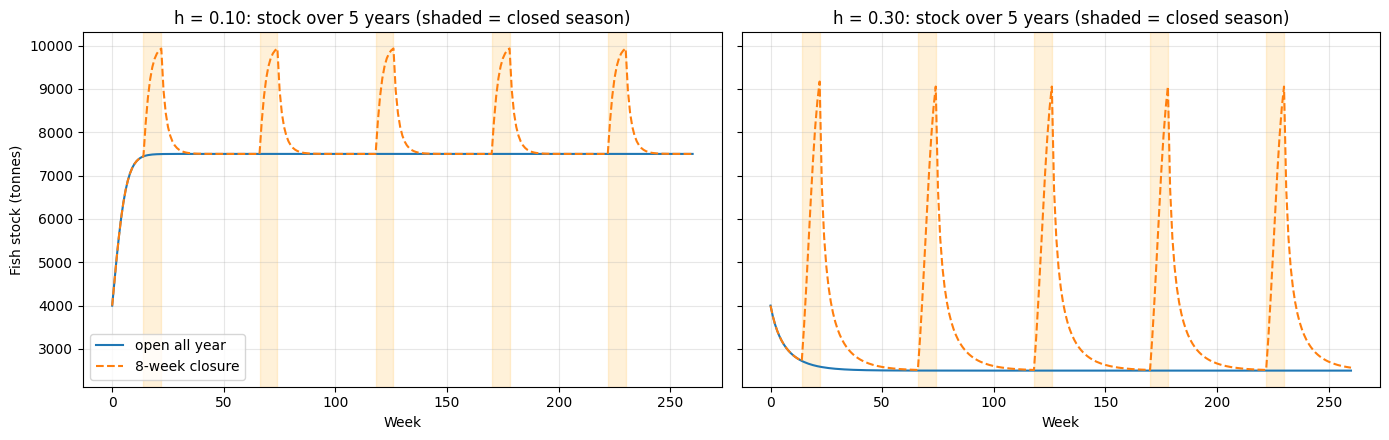

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, h in zip(axes, [0.10, 0.30]):
    for label, style in [("open all year", "-"), ("8-week closure", "--")]:
        ax.plot(ext_traj[(h, label)].stock, style, lw=1.5, label=label)
    for y in range(YEARS5):
        ax.axvspan(y * WEEKS + 14, y * WEEKS + 22, color="orange", alpha=0.15)
    ax.set_title(f"h = {h:.2f}: stock over 5 years (shaded = closed season)")
    ax.set_xlabel("Week")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Fish stock (tonnes)")
axes[0].legend()
fig.tight_layout()
plt.show()

**Interpretation.** The effect of a closed season depends on whether the fishery is already over-exploited. At or below the MSY rate ($h \le 0.20$) a closure *costs* revenue: 9–15% over five years. The stock is already near a productive level, and the fish left in the water during the closure grow logistically more slowly as the stock approaches $K$. At $h = 0.30$, beyond the MSY rate, the closure *raises* five-year revenue. The stock rebuilds towards the more productive range near $K/2$ during the closure, and the cooperative then harvests a larger stock for the remaining 44 weeks. In this model, a closed season is a tool for fixing over-fishing. A cooperative already fishing at or below $r/2$ gains more by simply keeping its rate there. (This model does not capture the real biological case for closures, protecting spawning fish and juveniles, so it understates their benefit.)

## Findings & Limitations

**Findings.** The sustainability question has a clear answer. Harvest rates up to $r/2 = 0.20$ are sustainable, and 0.20 itself delivers the theoretical MSY of 1,000 t/week while holding the stock at $K/2$. At $h = 0.30$ the stock is driven down to 2,500 t. Its long-run catch then falls to the same 750 t/week that $h = 0.10$ achieves while leaving three times as many fish in the lake. Year-one revenue hides this: $h = 0.30$ earns a one-off UGX 521 bn by fishing down the initial stock. Revenue risk is *Moderate* under every policy, and at the current $h = 0.10$ the 5% VaR is a shortfall of UGX 78 bn (17%) below expected annual revenue. Because the shortfall scales with revenue, the harvest rate decides *how much* the cooperative earns and whether that can last, while the *price* decides how risky it is. A closed season only pays off for an over-exploited fishery: +7% five-year revenue at $h = 0.30$, but −9% to −15% at lower rates. The cooperative's best policy is $h \approx 0.20$ with price hedging, not a closure.

**Limitations.** A weekly $r = 0.4$ is biologically extreme. It lets the stock rebound almost to $K$ within an 8-week closure, far faster than long-lived species such as Nile perch can reproduce. Biology is deterministic here: there is no recruitment variability and no shocks such as hypoxia or water-hyacinth outbreaks, so all simulated risk comes from price and the true risk is understated. Price and catch are assumed independent, whereas large landings depress local prices. The weekly CV mixes trend with volatility, so a detrended CV, or the CV of Monte Carlo annual revenue, would be a cleaner risk measure. The risk thresholds are a reasoned judgement, not an industry standard.